# Innlvering 1
## INF201
### Heidi Elvenes & Lisa Hoa 

##### Oppgave 1

Dataene ble hentet.
                       date  temperature
0 2025-01-01 00:00:00+00:00         -5.2
1 2025-01-01 00:00:00+00:00         -2.8
2 2025-01-02 00:00:00+00:00        -11.5
3 2025-01-02 00:00:00+00:00         -7.2
4 2025-01-03 00:00:00+00:00         -8.9


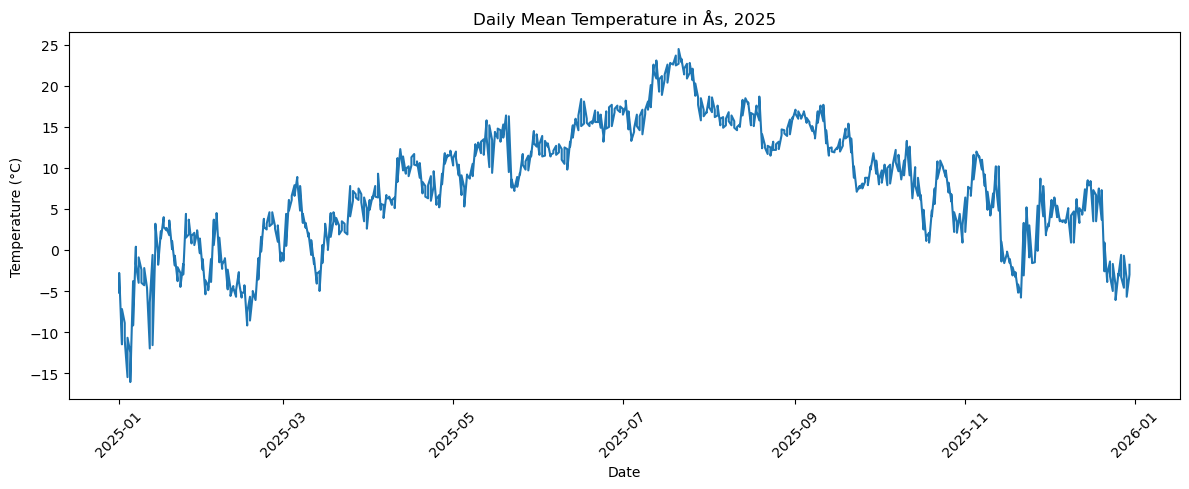

  Statistic  Temperature (°C)
0      Mean              7.90
1    Median              8.35
2   Minimum            -16.10
3   Maximum             24.50


In [70]:
# Bibliotek

import requests
import pandas as pd
import matplotlib.pyplot as plt

# Leser Client ID fra filen

with open("client_id.txt", "r") as file:
    client_id = file.read().strip()

# Adressen til Frost API
endpoint = "https://frost.met.no/observations/v0.jsonld"

# Bestemmer hvilke data vi vil hente
parameters = {
    "sources": "SN17850",
    "elements": "mean(air_temperature P1D)",
    "referencetime": "2025-01-01/2025-12-31"
}

# Sender forespørselen til Frost
response = requests.get(
    endpoint,
    params=parameters,
    auth=(client_id, "")
)

# Sjekker om forespørselen fungerte
if response.status_code == 200:
    print("Dataene ble hentet.")
else:
    print("Feil ved henting av data:", response.status_code)
    print(response.text)

# Leser svaret fra Frost
data = response.json()

# Lager en tom liste som skal inneholde dato og temperatur
temperature_data = []

# Går gjennom alle observasjonene
for item in data["data"]:

    # Henter datoen
    date = item["referenceTime"]

    # Går gjennom målingene for denne datoen
    for observation in item["observations"]:

        # Lagrer dato og temperatur
        temperature_data.append({
            "date": date,
            "temperature": observation["value"]
        })

# Gjør listen om til en Pandas-tabell
df = pd.DataFrame(temperature_data)

# Gjør datoene om til datoformat
df["date"] = pd.to_datetime(df["date"])

# Viser de første radene
print(df.head())

# Lager en figur
plt.figure(figsize=(12, 5))

# Tegner døgnmiddeltemperaturen
plt.plot(df["date"], df["temperature"])

# Legger til tittel og navn på aksene
plt.title("Daily Mean Temperature in Ås, 2025")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")

# Roterer datoene for bedre lesbarhet
plt.xticks(rotation=45)

# Tilpasser figuren
plt.tight_layout()

# Viser plottet
plt.show()

# Beregner gjennomsnitt, median, minimum og maksimum
mean_temperature = df["temperature"].mean()
median_temperature = df["temperature"].median()
min_temperature = df["temperature"].min()
max_temperature = df["temperature"].max()

# Samler resultatene i en tabell
summary = pd.DataFrame({
    "Statistic": ["Mean", "Median", "Minimum", "Maximum"],
    "Temperature (°C)": [
        mean_temperature,
        median_temperature,
        min_temperature,
        max_temperature
    ]
})

# Skriver ut tabellen med to desimaler
print(summary.round(2))



### Oppgave 2

Nedbørsdataene ble hentet.
                       date  precipitation
0 2025-01-01 00:00:00+00:00            5.4
1 2025-01-01 00:00:00+00:00            6.6
2 2025-01-02 00:00:00+00:00            0.0
3 2025-01-02 00:00:00+00:00            1.9
4 2025-01-03 00:00:00+00:00            0.1


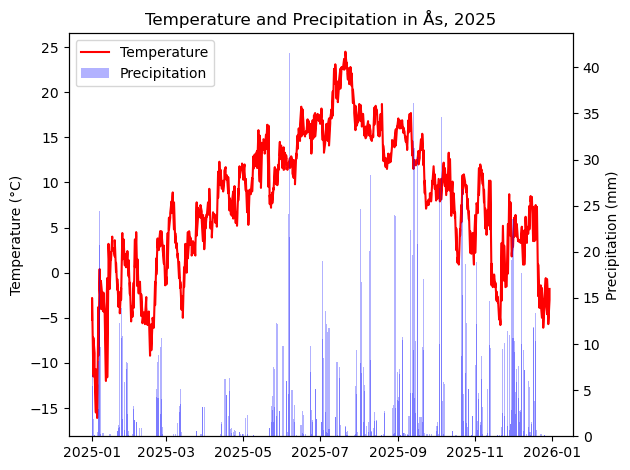

In [71]:

# Bestemmer hvilke nedbørsdata vi vil hente
parameters_precipitation = {
    "sources": "SN17850",
    "elements": "sum(precipitation_amount P1D)",
    "referencetime": "2025-01-01/2025-12-31"
}

# Henter data fra Frost
response_precipitation = requests.get(
    endpoint,
    params=parameters_precipitation,
    auth=(client_id, "")
)

# Sjekker om forespørselen fungerte
if response_precipitation.status_code == 200:
    print("Nedbørsdataene ble hentet.")
else:
    print("Feil:", response_precipitation.status_code)
    print(response_precipitation.text)


# Leser svaret fra Frost
precipitation_json = response_precipitation.json()

# Lager en tom liste
precipitation_data = []

# Går gjennom alle observasjonene
for item in precipitation_json["data"]:

    # Henter datoen
    date = item["referenceTime"]

    # Går gjennom målingene for datoen
    for observation in item["observations"]:

        # Lagrer dato og nedbør
        precipitation_data.append({
            "date": date,
            "precipitation": observation["value"]
        })

# Lager en DataFrame
df_precipitation = pd.DataFrame(precipitation_data)

# Gjør datoene om til datoformat
df_precipitation["date"] = pd.to_datetime(
    df_precipitation["date"]
)

# Viser de første radene
print(df_precipitation.head())


# Plotter temperatur
plt.plot(df["date"], df["temperature"],
         color="red", label="Temperature")

# Lager en ekstra y-akse for nedbør
plt.twinx()

# Plotter nedbør
plt.bar(df_precipitation["date"], df_precipitation["precipitation"],
        color="blue", alpha=0.3, label="Precipitation")

# Henter forklaringene fra begge aksene
lines1, labels1 = plt.gcf().axes[0].get_legend_handles_labels()
lines2, labels2 = plt.gcf().axes[1].get_legend_handles_labels()

# Viser begge i samme forklaringsboks
plt.legend(lines1 + lines2, labels1 + labels2, loc="upper left")

# Tittel og navn på aksene
plt.title("Temperature and Precipitation in Ås, 2025")
plt.xlabel("Date")
plt.gcf().axes[0].set_ylabel("Temperature (°C)")
plt.gcf().axes[1].set_ylabel("Precipitation (mm)")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()





#### Oppgave 3

Dataene ble hentet!
                       date  temperature
0 1925-01-01 00:00:00+00:00          1.3
1 1925-01-02 00:00:00+00:00          4.1
2 1925-01-03 00:00:00+00:00          2.1
3 1925-01-04 00:00:00+00:00          0.1
4 1925-01-05 00:00:00+00:00         -2.2
Antall målinger i 2025: 364
Antall målinger i 1925: 364


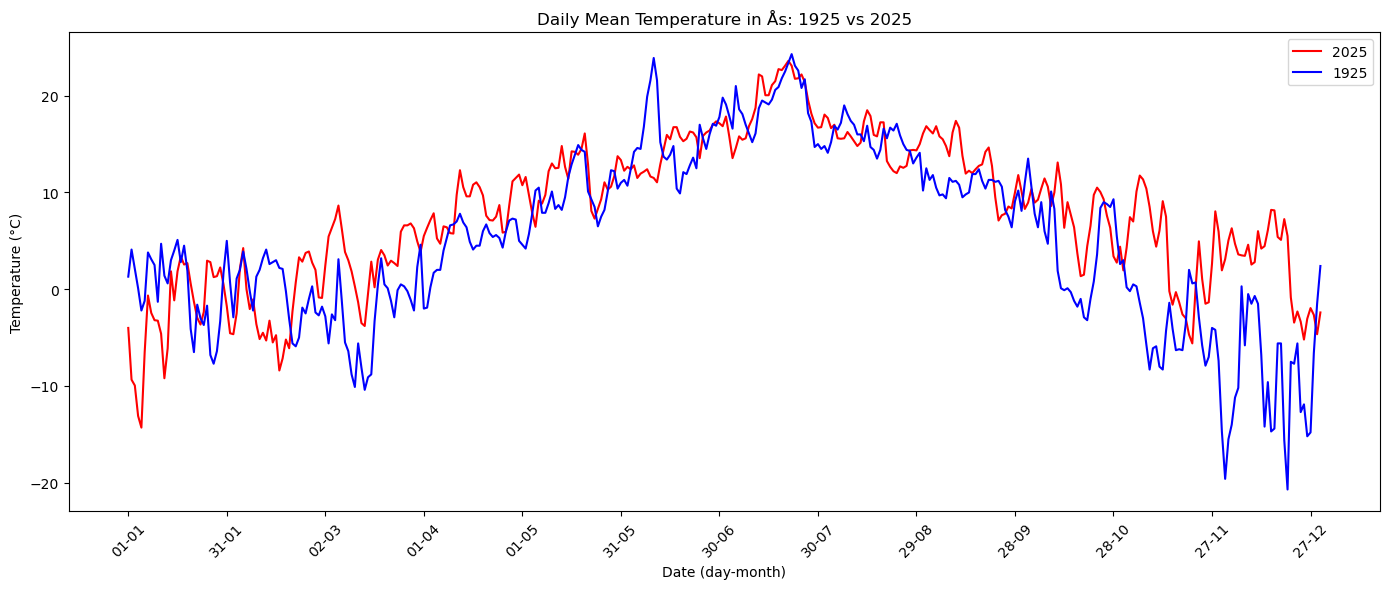

  Statistic  1925 (°C)  2025 (°C)
0      Mean       5.31       7.90
1    Median       5.30       8.33
2   Minimum     -20.70     -14.30
3   Maximum      24.30      23.60


In [72]:
# Bestemmer hvilke temperaturdata vi vil hente
parameters_old = {
    "sources": "SN17850",
    "elements": "mean(air_temperature P1D)",
    "referencetime": "1925-01-01/1925-12-31"
}

# Henter data fra Frost
response_old = requests.get(
    endpoint,
    params=parameters_old,
    auth=(client_id, "")
)

# Sjekker om forespørselen fungerte
if response_old.status_code == 200:
    print("Dataene ble hentet!")
else:
    print("Feil ved henting av data:", response_old.status_code)

# Leser svaret fra Frost
old_json = response_old.json()

# Lager en tom liste for temperaturdataene
old_temperature_data = []

# Går gjennom alle observasjonene
for item in old_json["data"]:

    # Henter datoen
    date = item["referenceTime"]

    # Går gjennom målingene for datoen
    for observation in item["observations"]:

        # Lagrer dato og temperatur
        old_temperature_data.append({
            "date": date,
            "temperature": observation["value"]
        })

# Gjør listen om til en tabell
df_old = pd.DataFrame(old_temperature_data)

# Gjør datoene om til datoformat
df_old["date"] = pd.to_datetime(df_old["date"])

# Viser de første radene
print(df_old.head())

# Gjør datoene om til datoformat uten klokkeslett
df["date"] = pd.to_datetime(df["date"]).dt.date
df_old["date"] = pd.to_datetime(df_old["date"]).dt.date

# Samler målinger fra samme dato og beregner gjennomsnittet
df = df.groupby("date", as_index=False)["temperature"].mean()
df_old = df_old.groupby("date", as_index=False)["temperature"].mean()

# Kontrollerer antall datoer
print("Antall målinger i 2025:", len(df))
print("Antall målinger i 1925:", len(df_old))

# Lager måned og dag for begge årene
df["day"] = pd.to_datetime(df["date"]).astype(str).str[5:]
df_old["day"] = pd.to_datetime(df_old["date"]).astype(str).str[5:]

# Lager et stort plott
plt.figure(figsize=(14, 6))

# Plotter temperaturen for 2025
plt.plot(df["day"], df["temperature"],
         color="red", label="2025")

# Plotter temperaturen for 1925
plt.plot(df_old["day"], df_old["temperature"],
         color="blue", label="1925")

# Legger til tittel og navn på aksene
plt.title("Daily Mean Temperature in Ås: 1925 vs 2025")
plt.xlabel("Date (day-month)")
plt.ylabel("Temperature (°C)")

# Viser forklaringsboks
plt.legend()

# Viser datoene med dag først, omtrent én gang i måneden
plt.xticks(
    range(0, len(df), 30),
    pd.to_datetime(df["day"].iloc[::30], format="%m-%d").dt.strftime("%d-%m"),
    rotation=45
)

# Tilpasser plottet og viser det
plt.tight_layout()
plt.show()

# Beregner statistikk for 2025
mean_2025 = df["temperature"].mean()
median_2025 = df["temperature"].median()
min_2025 = df["temperature"].min()
max_2025 = df["temperature"].max()

# Beregner statistikk for 1925
mean_1925 = df_old["temperature"].mean()
median_1925 = df_old["temperature"].median()
min_1925 = df_old["temperature"].min()
max_1925 = df_old["temperature"].max()

# Lager en tabell med resultatene
summary = pd.DataFrame({
    "Statistic": ["Mean", "Median", "Minimum", "Maximum"],
    "1925 (°C)": [
        mean_1925, median_1925, min_1925, max_1925
    ],
    "2025 (°C)": [
        mean_2025, median_2025, min_2025, max_2025
    ]
})

# Skriver ut tabellen med to desimaler
print(summary.round(2))
   


#### Oppgave 4

In [73]:
#Bibliotek
import requests
import yaml

# Bestemmer hvilke data vi vil hente
parameters = {
    "sources": "SN17850",
    "elements": "max(air_temperature P1D)",
    "referencetime": "2025-01-01/2025-12-31"
}

# Henter data fra Frost
response = requests.get(
    endpoint,
    params=parameters,
    auth=(client_id, "")
)

# Sjekker om forespørselen fungerte
if response.status_code == 200:
    print("Dataene ble hentet!")
else:
    print("Feil:", response.status_code)
    print(response.text)

def count_heatwaves(station, year):

    # Bestemmer hvilke data vi vil hente
    parameters = {
        "sources": station,
        "elements": "max(air_temperature P1D)",
        "referencetime": str(year) + "-01-01/" + str(year) + "-12-31"
    }

    # Henter data fra Frost
    response = requests.get(
        endpoint,
        params=parameters,
        auth=(client_id, "")
    )

    # Sjekker om forespørselen fungerte
    if response.status_code != 200:
        print("Feil ved henting av data:", response.status_code)
        return

    # Leser dataene
    data = response.json()

    # Teller sammenhengende varme dager
    consecutive_days = 0
    heatwaves = 0

    for item in data["data"]:
        for observation in item["observations"]:

            temperature = observation["value"]

            # Sjekker om maksimumstemperaturen er minst 27 grader
            if temperature >= 27:
                consecutive_days += 1
            else:
                # Fem eller flere dager betyr én hetebølge
                if consecutive_days >= 5:
                    heatwaves += 1

                # Starter tellingen på nytt
                consecutive_days = 0

    # Kontrollerer også de siste dagene i året
    if consecutive_days >= 5:
        heatwaves += 1

    # Lager en oppsummering
    summary = {
        "station": station,
        "year": year,
        "number_of_heatwaves": heatwaves
    }

    # Skriver resultatet til en YAML-fil
    with open("heatwaves.yml", "w") as file:
        yaml.dump(summary, file, sort_keys=False)

    # Skriver resultatet ut
    print(summary)

# Teller hetebølger i Ås i 2025
count_heatwaves("SN17850", 2025)

Dataene ble hentet!
{'station': 'SN17850', 'year': 2025, 'number_of_heatwaves': 1}


#### Oppgave 5

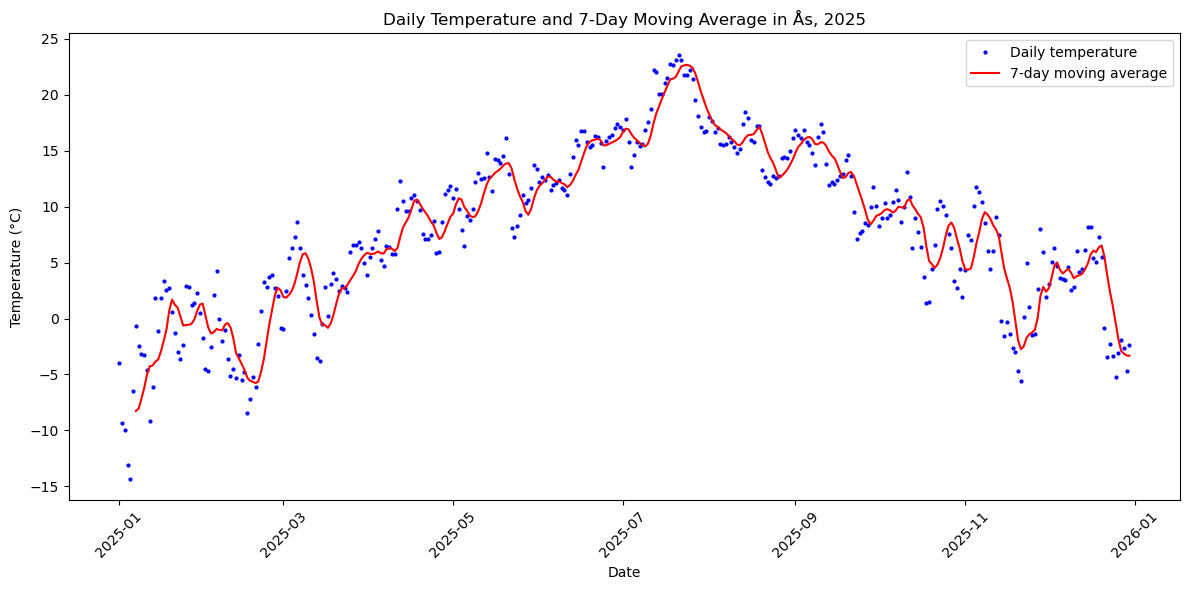

In [74]:
# Lager en funksjon som beregner glidende gjennomsnitt
def moving_average(temperature):

    # Beregner gjennomsnittet for de siste 7 dagene
    average = temperature.rolling(window=7).mean()

    return average
# Beregner 7-dagers glidende gjennomsnitt
df["moving_average"] = moving_average(df["temperature"])

# Lager et stort plott
plt.figure(figsize=(12, 6))

# Viser daglige temperaturer som punkter
plt.plot(df["date"], df["temperature"],
         "o", markersize=2, color="blue",
         label="Daily temperature")

# Viser glidende gjennomsnitt som en linje
plt.plot(df["date"], df["moving_average"],
         color="red", label="7-day moving average")

# Legger til tittel og aksetekster
plt.title("Daily Temperature and 7-Day Moving Average in Ås, 2025")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")

# Viser forklaringsboks
plt.legend()

# Roterer datoene
plt.xticks(rotation=45)

# Tilpasser og viser plottet
plt.tight_layout()
plt.show()